In [1]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.modelos import carregar_sin, backtest, mape

sin = carregar_sin()
print("treino a partir de:", sin.index.min().date(), "| último dia:", sin.index.max().date(), "|", len(sin), "dias")

# Simula o uso real: uma previsão por semana nos últimos 12 meses, cada uma com 14 dias à frente,
# treinando sempre só com o que era conhecido até aquele dia
origens = pd.date_range(end=sin.index.max() - pd.Timedelta(days=14), periods=52, freq="7D")
resultado = backtest(sin, origens)
print(len(origens), "previsões simuladas,", len(resultado), "dias previstos")

erros = mape(resultado).round(2)
erros.to_frame("MAPE (%)")

treino a partir de: 2023-04-29 | último dia: 2026-10-23 | 1274 dias
52 previsões simuladas, 728 dias previstos


,MAPE (%)
ingenuo,3.91
harmonica,2.90
boosting,2.85
combinado,2.55


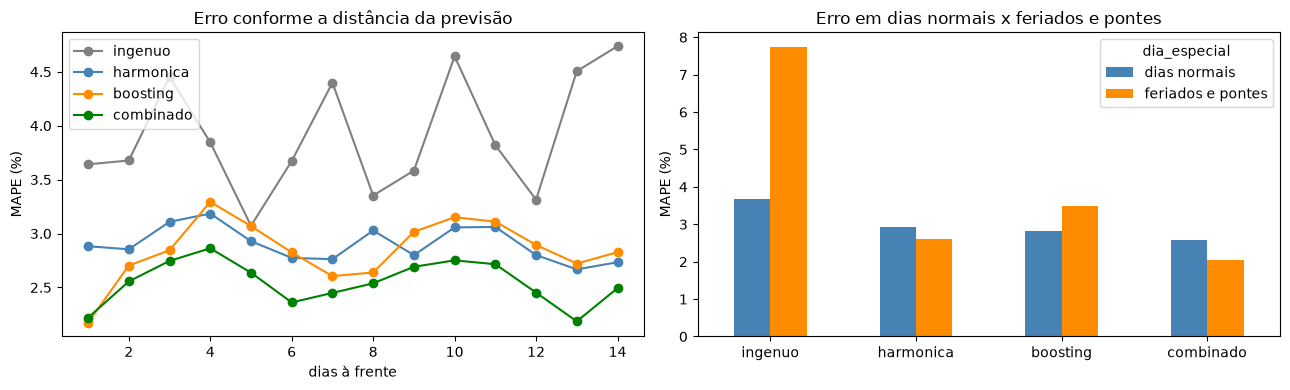

,ingenuo,harmonica,boosting,combinado
dia_especial,,,,
dias normais,3.67,2.92,2.81,2.58
feriados e pontes,7.74,2.60,3.50,2.03


In [2]:
from src.feriados import calendario
from src.modelos import MODELOS

cores = {"ingenuo": "gray", "harmonica": "steelblue", "boosting": "darkorange", "combinado": "green"}

# 1) Erro por dias à frente
por_horizonte = resultado.groupby("dias_a_frente").apply(mape)

# 2) Erro em feriados/pontes x dias normais
cal = calendario(resultado["data"])
resultado["dia_especial"] = ((cal["feriado"] + cal["meio_feriado"] + cal["ponte"]) > 0).values
por_tipo = resultado.groupby("dia_especial").apply(mape).rename(index={False: "dias normais", True: "feriados e pontes"})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for m in MODELOS:
    ax1.plot(por_horizonte.index, por_horizonte[m], marker="o", color=cores[m], label=m)
ax1.set_xlabel("dias à frente"); ax1.set_ylabel("MAPE (%)"); ax1.set_title("Erro conforme a distância da previsão")
ax1.legend()
por_tipo.T.plot.bar(ax=ax2, color=["steelblue", "darkorange"], rot=0)
ax2.set_ylabel("MAPE (%)"); ax2.set_title("Erro em dias normais x feriados e pontes")
plt.tight_layout()
plt.savefig("../reports/figures/erros_modelos.png", dpi=120)
plt.show()

por_tipo.round(2)

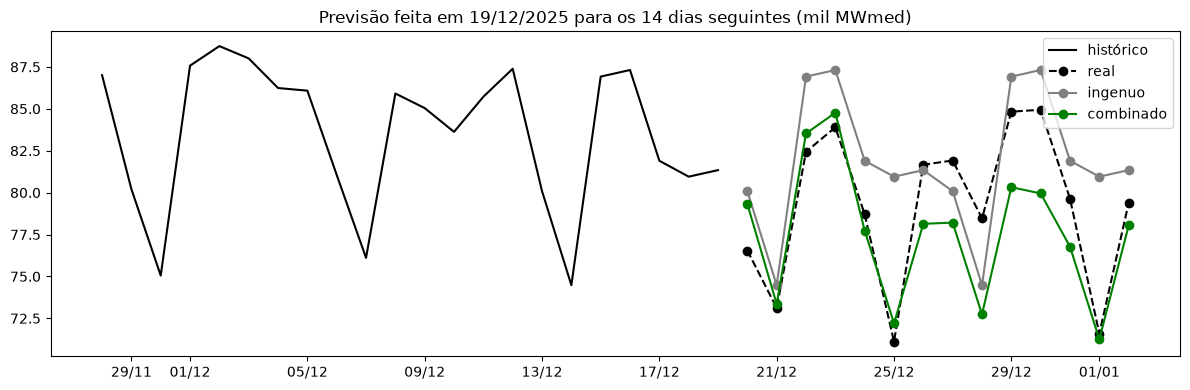

ingenuo      4.66
harmonica    3.14
boosting     5.80
combinado    3.01
dtype: float64

In [3]:
import matplotlib.dates as mdates

# Exemplo: a previsão feita perto do fim de ano (Natal e Ano Novo no horizonte)
origem_exemplo = min(origens, key=lambda d: abs(d - pd.Timestamp("2025-12-20")))
ex = resultado[resultado["origem"] == origem_exemplo].set_index("data")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sin[origem_exemplo - pd.Timedelta(days=21):origem_exemplo] / 1000, color="black", label="histórico")
ax.plot(ex["real"] / 1000, color="black", ls="--", marker="o", label="real")
for m in ["ingenuo", "combinado"]:
    ax.plot(ex[m] / 1000, color=cores[m], marker="o", label=m)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title(f"Previsão feita em {origem_exemplo:%d/%m/%Y} para os 14 dias seguintes (mil MWmed)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/exemplo_fim_de_ano.png", dpi=120)
plt.show()

mape(ex.reset_index()).round(2)